In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("housing.csv")


display(df.head())


print("Dataset shape:", df.shape)


df.info()


print("\nMissing values in each column:")
print(df.isnull().sum())


display(df.describe())


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Dataset shape: (20640, 10)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Missing values in each column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn jupyter ipykernel


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached notebook-7.6.3-py3-none-any.whl.metadata (10 kB)
  Using cached jupyter_console-6.6.3-py3-none-any.whl.metadata (5.8 kB)
  Using cached nbconvert-7.17.2-py3-none-any.whl.metadata (8.4 kB)
  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached jupyterlab-4.6.4-py3-none-any.whl.metadata (16 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached widgetsnbextension-4.0.16-py3-none


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


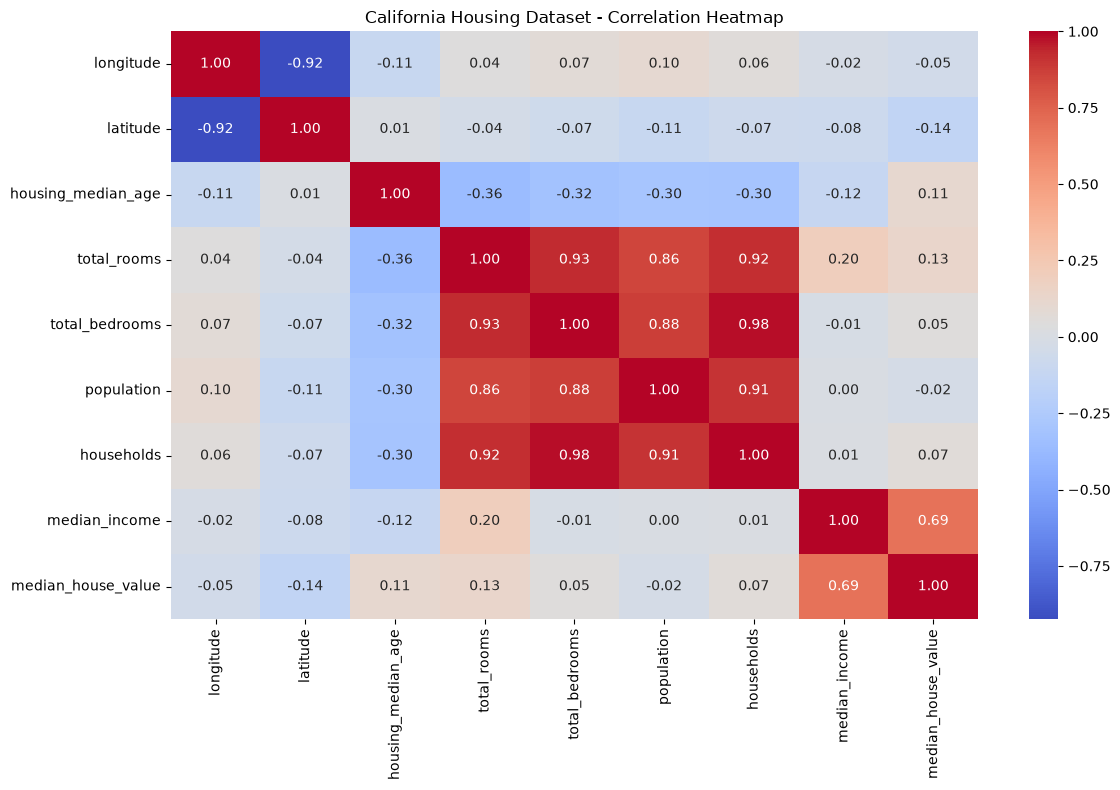

In [ ]:


numeric_df = df.select_dtypes(include=np.number)


plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("California Housing Dataset - Correlation Heatmap")
plt.tight_layout()
plt.show()


In [ ]:


print("Missing values before:")
print(df.isnull().sum())


for column in df.select_dtypes(include=np.number).columns:
    df[column] = df[column].fillna(df[column].median())


for column in df.select_dtypes(exclude=np.number).columns:
    df[column] = df[column].fillna(df[column].mode()[0])

print("\nMissing values after:")
print(df.isnull().sum())


Missing values before:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Missing values after:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split



df = pd.read_csv("housing.csv")


X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (16512, 9)
Testing features: (4128, 9)
Training target: (16512,)
Testing target: (4128,)


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin

class HousingFeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        
        X["rooms_per_household"] = (
            X["total_rooms"] / X["households"].replace(0, np.nan)
        )
        X["bedrooms_per_room"] = (
            X["total_bedrooms"] / X["total_rooms"].replace(0, np.nan)
        )
        X["population_per_household"] = (
            X["population"] / X["households"].replace(0, np.nan)
        )
        X["income_x_rooms"] = X["median_income"] * X["total_rooms"]

        return X


categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

preprocessing_pipeline = Pipeline([
    ("features", HousingFeatureEngineer()),
    ("preprocessor", preprocessor)
])

print("Feature engineering and preprocessing pipeline created.")
print("Numerical columns:", numeric_features)
print("Categorical columns:", categorical_features)


Feature engineering and preprocessing pipeline created.
Numerical columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical columns: ['ocean_proximity']


C:\Users\Asus\AppData\Local\Temp\ipykernel_2676\336565717.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [ ]:

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


ols_model = Pipeline([
    ("features", HousingFeatureEngineer()),
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

ols_model.fit(X_train, y_train)
ols_predictions = ols_model.predict(X_test)


ridge_pipeline = Pipeline([
    ("features", HousingFeatureEngineer()),
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

ridge_search = GridSearchCV(
    ridge_pipeline,
    {"regressor__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
ridge_search.fit(X_train, y_train)
ridge_predictions = ridge_search.predict(X_test)


lasso_pipeline = Pipeline([
    ("features", HousingFeatureEngineer()),
    ("preprocessor", preprocessor),
    ("regressor", Lasso(max_iter=20000))
])

lasso_search = GridSearchCV(
    lasso_pipeline,
    {"regressor__alpha": [0.001, 0.01, 0.1, 1, 10]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
lasso_search.fit(X_train, y_train)
lasso_predictions = lasso_search.predict(X_test)

print("OLS, Ridge, and Lasso training completed.")
print("Best Ridge parameters:", ridge_search.best_params_)
print("Best Lasso parameters:", lasso_search.best_params_)


OLS, Ridge, and Lasso training completed.
Best Ridge parameters: {'regressor__alpha': 1}
Best Lasso parameters: {'regressor__alpha': 1}


In [ ]:

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


ols_model = Pipeline([
    ("features", HousingFeatureEngineer()),
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

ols_model.fit(X_train, y_train)
ols_predictions = ols_model.predict(X_test)


ridge_pipeline = Pipeline([
    ("features", HousingFeatureEngineer()),
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

ridge_search = GridSearchCV(
    ridge_pipeline,
    {"regressor__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
ridge_search.fit(X_train, y_train)
ridge_predictions = ridge_search.predict(X_test)


lasso_pipeline = Pipeline([
    ("features", HousingFeatureEngineer()),
    ("preprocessor", preprocessor),
    ("regressor", Lasso(max_iter=20000))
])

lasso_search = GridSearchCV(
    lasso_pipeline,
    {"regressor__alpha": [0.001, 0.01, 0.1, 1, 10]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
lasso_search.fit(X_train, y_train)
lasso_predictions = lasso_search.predict(X_test)

print("OLS, Ridge, and Lasso training completed.")
print("Best Ridge parameters:", ridge_search.best_params_)
print("Best Lasso parameters:", lasso_search.best_params_)


c:\Users\Asus\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


OLS, Ridge, and Lasso training completed.
Best Ridge parameters: {'regressor__alpha': 1}
Best Lasso parameters: {'regressor__alpha': 1}


In [19]:

models = {
    "OLS": ols_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

results = []

for model_name, predictions in models.items():
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(4))


,Model,RMSE,MAE,R2
0,OLS,70059.1933,50670.4892,0.6254
2,Lasso,70059.2810,50670.5870,0.6254
1,Ridge,70066.0211,50676.9222,0.6254


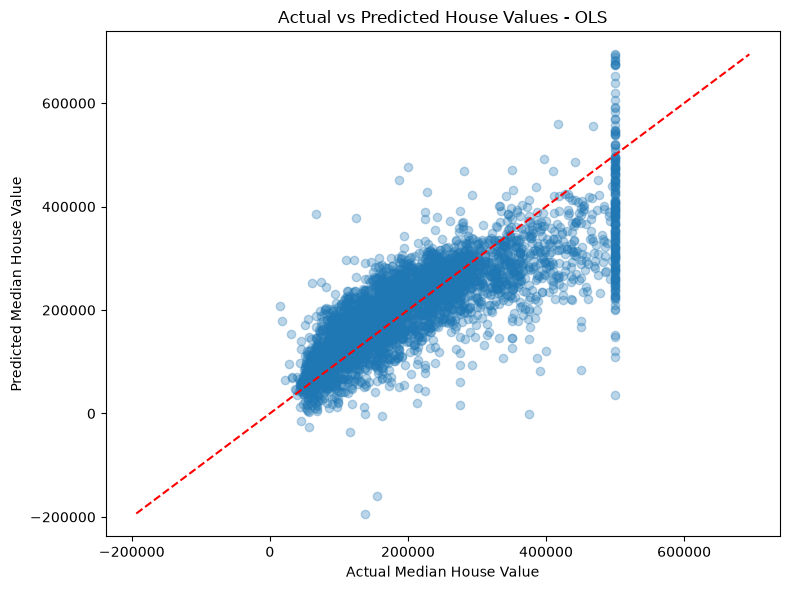

In [18]:

best_model_name = results_df.iloc[0]["Model"]
best_predictions = models[best_model_name]

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_predictions, alpha=0.3)
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title(f"Actual vs Predicted House Values - {best_model_name}")

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")

plt.tight_layout()
plt.show()


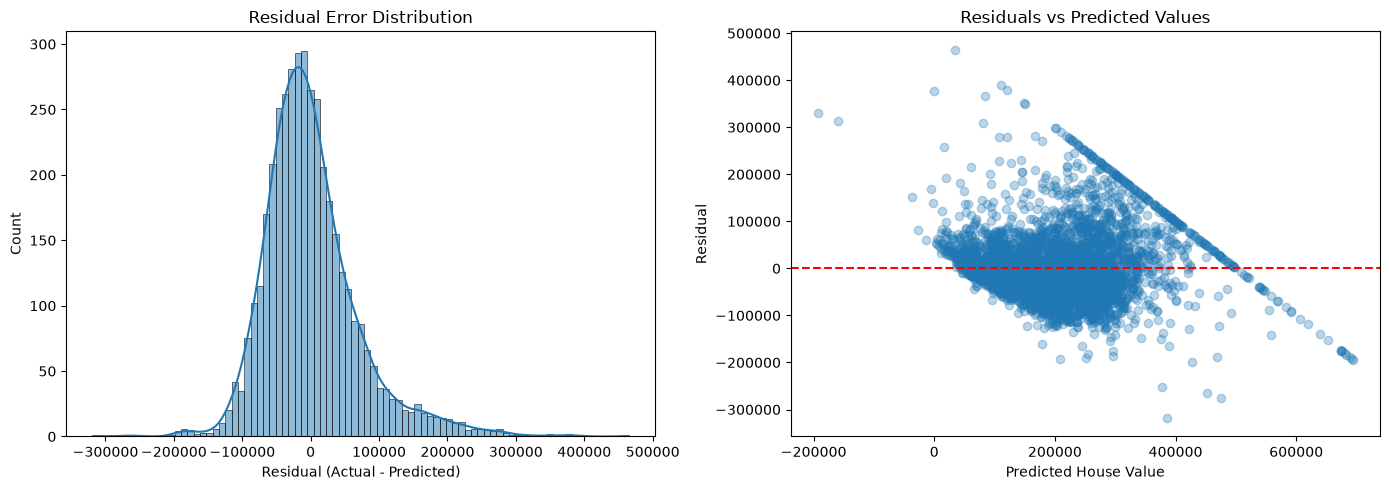

Selected model: OLS
Mean residual: 1040.85


In [17]:

residuals = y_test - best_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title("Residual Error Distribution")
axes[0].set_xlabel("Residual (Actual - Predicted)")

axes[1].scatter(best_predictions, residuals, alpha=0.3)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs Predicted Values")
axes[1].set_xlabel("Predicted House Value")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

print("Selected model:", best_model_name)
print("Mean residual:", round(residuals.mean(), 2))


In [16]:

results_df.to_csv("model_comparison.csv", index=False)
print("Model comparison saved to model_comparison.csv")


Model comparison saved to model_comparison.csv


In [15]:

from sklearn.compose import ColumnTransformer, make_column_selector

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline,
     make_column_selector(dtype_include=np.number)),
    ("cat", categorical_pipeline,
     make_column_selector(dtype_include=["object", "category"]))
])

print("Preprocessor updated successfully!")


Preprocessor updated successfully!
